# Análisis espacial de la recuperación (OE3)

Contrasta las hipótesis H1 y H2 sobre la estructura territorial de la caída inicial y de la recuperación.

**Requiere** el notebook 04 ejecutado (`dataset_analitico_mate.csv`) y las librerías `libpysal`, `esda` y `statsmodels`.

### El contraste que importa

Detectar autocorrelación espacial positiva en un indicador escolar chileno **no es, por sí solo, un hallazgo**. El sistema presenta uno de los niveles de segregación socioeconómica más altos de la OCDE, de modo que la composición social de cada escuela está determinada en gran medida por su ubicación residencial. Bajo esas condiciones casi cualquier variable correlacionada con el nivel socioeconómico exhibirá un Moran positivo por construcción.

La pregunta informativa es si **queda estructura espacial después de descontar la composición**. Por eso el contraste central (H1) se aplica sobre los residuos de un modelo que ya controla grupo socioeconómico, dependencia, ruralidad y puntaje pre-pandemia.

> **Revisión del 24-oct-2026 (auditoría de cuadernos y código).** Cuatro correcciones en el código (`espacial.py` y `robustez.py`, versión 1.1.0 del paquete):

1. **Modelo de línea base.** Con el optimizador L-BFGS el ajuste quedaba en un borde degenerado: log-verosimilitud infinita, intercepto fijo en 0 y varianza comunal reportada como 0. Ahora se ajusta con Powell, que converge: la varianza comunal es pequeña pero **no nula** (6,0 en la caída frente a 292 de varianza residual, cerca del 2 %; 0,57 frente a 44 en la recuperación). Los residuos tienen media 0 (antes, 103).
2. **Contracción por número de evaluados.** Se multiplicaba por la confiabilidad un residuo sin centrar, lo que agregaba una variación artificial ligada al tamaño de la escuela. Ahora se centra antes de contraer.
3. **Semillas fijas** en Moran y LISA (2026): los conteos ya no cambian de una ejecución a otra.
4. **Coordenadas repetidas.** Cinco escuelas comparten coordenadas con otra y daban peso infinito con distancia inversa (el aviso `divide by zero`). Se separan 50 m sin cambiar sus vecinos.

**Salidas esperadas** (Matemática, muestra de 2.821):

| Celda | Antes | Ahora |
|---|---|---|
| Moran de `recuperacion_relativa` | 0,0105 (n = 2.721) | 0,0068 (n = 1.856), p = 0,23 |
| Moran del residuo de la caída | 0,0332 (p = 0,0003) | 0,0316 (p = 0,0005) |
| Moran del residuo de la recuperación | 0,0165 (p = 0,030) | 0,0161 (p = 0,031) |
| `var_efecto_aleatorio` | 0,0 y 0,0 | 6,02 y 0,57 |
| LISA del residuo de la caída | 413 sin corregir, 0 tras FDR | 413 y 0 |
| Sensibilidad del residuo de la caída | 0,027 a 0,034 | 0,025 a 0,032; con k = 4 (0,0295) queda bajo su mínimo detectable (0,0309) y con 10 km queda en el límite (0,0252 frente a 0,0248) |
| Moran contraído | 0,0627 | 0,0364 |
| Moran corregido por atenuación | 0,0418 | 0,0397 |

La conclusión de H1 no cambia de signo, pero sí de tono: el Moran contraído ya no "sube" a casi el doble, queda prácticamente igual al observado. Ver la celda de robustez para la recuperación, que es frágil.

In [1]:
import sys
from pathlib import Path
import warnings

for m in list(sys.modules):
    if m == "simce_panel" or m.startswith("simce_panel."):
        del sys.modules[m]
candidatos = [Path.cwd() / "simce_panel" / "src", Path.cwd().parent / "src", Path.cwd() / "src"]
RUTA_SRC = next((p for p in candidatos if (p / "simce_panel" / "__init__.py").exists()), None)
if RUTA_SRC is None:
    raise FileNotFoundError("No encontré 'src/simce_panel'.")
sys.path.insert(0, str(RUTA_SRC))

import numpy as np
import pandas as pd
import simce_panel as sp
E = sp.espacial
sp.configurar_logging()

# libpysal advierte cuando la red de vecinos tiene componentes desconectados
# (Rapa Nui, Juan Fernández, la Antártica). Es esperable y no afecta el cálculo.
warnings.filterwarnings("ignore", message=".*not fully connected.*")
print("simce_panel", sp.__version__)

simce_panel 1.1.0


In [2]:
BASE_DIR = "."
cfg = sp.Config.desde_base(BASE_DIR)
MATERIA = "mate"

datos = sp.io_datos.leer_csv(cfg.ruta_salida(f"dataset_analitico_{MATERIA}.csv"))
m = datos[datos["muestra_analitica"].fillna(False)].dropna(
    subset=["latitud", "longitud"]).copy()
print("Establecimientos con coordenadas en la muestra analítica:", len(m))

Establecimientos con coordenadas en la muestra analítica: 2821


## 1. Matriz de pesos espaciales

Se usan los **k vecinos más cercanos** y no contigüidad, porque los establecimientos son puntos y no comparten fronteras. Las coordenadas se proyectan a kilómetros antes de medir distancias: en Chile un grado de longitud mide unos 104 km en Arica y 62 km en Punta Arenas, de modo que usar grados como plano haría que el vecindario de un colegio austral fuera geográficamente más ancho, sesgando el análisis en la dimensión que se quiere estudiar.

In [3]:
K = 8
w = E.construir_pesos(m, k=K)
print(f"Matriz de pesos: {w.n} unidades, k={K}, estandarizada por filas.")

15:14:57 | INFO    | simce_panel.espacial | Pesos espaciales: 2821 unidades, k=8.


Matriz de pesos: 2821 unidades, k=8, estandarizada por filas.


## 2. Comparación decisiva: niveles frente a cambios

Antes de contrastar las hipótesis conviene ver si la autocorrelación se comporta igual en los **niveles** de puntaje que en los **cambios**. La segregación predice fuerte autocorrelación en los niveles; si los cambios la tuvieran en magnitud similar, habría un fenómeno territorial propio.

**Revisión del 1-oct (comentario 38).** La comparación con los niveles orienta, pero la pertinente para H1 es otra: el Moran **crudo** frente al de los **residuos de la misma variable** (sección 3). Si ambos son casi iguales, las covariables no explican la estructura espacial de los cambios, lo que es un hallazgo en sí.

In [4]:
filas = []
for col in ["puntaje_pre", "puntaje_impacto", "caida_inicial",
            "recuperacion", "recuperacion_relativa"]:
    if col not in m.columns:
        continue
    d = m.dropna(subset=[col])
    wd = E.construir_pesos(d, k=K)
    filas.append(E.moran_global(d[col], wd, permutaciones=9999, etiqueta=col))

comparacion = pd.DataFrame(filas)
comparacion["tipo"] = ["nivel", "nivel", "cambio", "cambio", "cambio"][:len(comparacion)]
comparacion

15:14:57 | INFO    | simce_panel.espacial | Pesos espaciales: 2821 unidades, k=8.


15:14:59 | INFO    | simce_panel.espacial | Pesos espaciales: 2821 unidades, k=8.


15:15:00 | INFO    | simce_panel.espacial | Pesos espaciales: 2821 unidades, k=8.


15:15:00 | INFO    | simce_panel.espacial | Pesos espaciales: 2821 unidades, k=8.


15:15:01 | INFO    | simce_panel.espacial | Pesos espaciales: 1856 unidades, k=8.


,variable,n,I,E[I],z,p_sim,tipo
0,puntaje_pre,2821,0.1459,-0.0004,16.88,0.0001,nivel
1,puntaje_impacto,2821,0.1797,-0.0004,20.81,0.0001,nivel
2,caida_inicial,2821,0.0366,-0.0004,4.23,0.0001,cambio
3,recuperacion,2821,0.0203,-0.0004,2.39,0.0097,cambio
4,recuperacion_relativa,1856,0.0068,-0.0005,0.69,0.2349,cambio


**Cómo leerlo.** Si los niveles muestran un índice de Moran varias veces mayor que los cambios, la conclusión es que la geografía estructura *dónde están* los buenos y malos resultados, pero no *cómo cambiaron*. Es el contraste que orienta toda la interpretación posterior.

### 2.1 Sensibilidad al número de vecinos

La elección de `k` es arbitraria. Este reporte documenta que la conclusión no depende de un valor particular.

In [5]:
E.sensibilidad_k(m, "caida_inicial", ks=(4, 6, 8, 12, 20), permutaciones=999)

15:15:01 | INFO    | simce_panel.espacial | Pesos espaciales: 2821 unidades, k=4.


15:15:01 | INFO    | simce_panel.espacial | Pesos espaciales: 2821 unidades, k=6.


15:15:01 | INFO    | simce_panel.espacial | Pesos espaciales: 2821 unidades, k=8.


15:15:02 | INFO    | simce_panel.espacial | Pesos espaciales: 2821 unidades, k=12.


15:15:02 | INFO    | simce_panel.espacial | Pesos espaciales: 2821 unidades, k=20.


,k,variable,n,I,z,p_sim
0,4,caida_inicial,2821,0.0465,3.79,0.001
1,6,caida_inicial,2821,0.0446,4.40,0.001
2,8,caida_inicial,2821,0.0366,4.30,0.001
3,12,caida_inicial,2821,0.0278,3.97,0.001
4,20,caida_inicial,2821,0.0199,3.65,0.001


## 3. H1 — ¿Persiste la autocorrelación tras controlar la composición?

Se ajusta el modelo lineal jerárquico de la línea base (intercepto aleatorio por comuna, con grupo socioeconómico, dependencia, ruralidad, puntaje PRE e indicador de ruptura) y se calcula el índice de Moran **sobre sus residuos**.

In [6]:
resultados_h1 = []
modelos = {}
for dep in ["caida_inicial", "recuperacion"]:
    res, d = E.modelo_base(m, dep)
    modelos[dep] = (res, d)
    wd = E.construir_pesos(d, k=K)
    crudo = E.moran_global(d[dep], wd, permutaciones=9999, etiqueta=f"{dep} (cruda)")
    resid = E.moran_global(d["residuo"], wd, permutaciones=9999,
                           etiqueta=f"{dep} (residuo)")
    for r in (crudo, resid):
        r["var_efecto_aleatorio"] = d.attrs.get("var_efecto_aleatorio")
        resultados_h1.append(r)

pd.DataFrame(resultados_h1)

15:15:02 | INFO    | simce_panel.espacial | Modelo base: caida_inicial ~ cod_grupo_cat + cod_depe1_cat + cod_rural_rbd_cat + puntaje_pre + ruptura_sostenida | agrupado por comuna_dir | n=2821


15:15:03 | INFO    | simce_panel.espacial | Varianza de la dependiente explicada por el modelo: 45.5 %.


15:15:03 | INFO    | simce_panel.espacial | Pesos espaciales: 2821 unidades, k=8.


15:15:04 | INFO    | simce_panel.espacial | Modelo base: recuperacion ~ cod_grupo_cat + cod_depe1_cat + cod_rural_rbd_cat + puntaje_pre + ruptura_sostenida | agrupado por comuna_dir | n=2821


15:15:05 | INFO    | simce_panel.espacial | Varianza de la dependiente explicada por el modelo: 1.5 %.


15:15:05 | INFO    | simce_panel.espacial | Pesos espaciales: 2821 unidades, k=8.


,variable,n,I,E[I],z,p_sim,var_efecto_aleatorio
0,caida_inicial (cruda),2821,0.0366,-0.0004,4.23,0.0001,6.016142
1,caida_inicial (residuo),2821,0.0316,-0.0004,3.65,0.0006,6.016142
2,recuperacion (cruda),2821,0.0203,-0.0004,2.39,0.0097,0.565861
3,recuperacion (residuo),2821,0.0161,-0.0004,1.91,0.0307,0.565861


**Sobre el efecto aleatorio (corregido el 24-oct-2026).** La versión anterior de este texto decía que la varianza comunal era nula y que eso era un resultado. No lo era: el optimizador L-BFGS se detenía en un borde degenerado (log-verosimilitud infinita e intercepto fijo en 0). Con Powell el modelo converge y la varianza comunal es pequeña pero positiva: cerca del 2 % de la varianza no explicada en la caída y del 1 % en la recuperación. El módulo verifica ahora que la log-verosimilitud sea finita y avisa si los residuos no tienen media cercana a 0.

Los residuos siguen siendo marginales (solo parte fija), de modo que la pequeña variación comunal queda dentro de ellos y es parte de lo que el Moran mide.

In [7]:
# Coeficientes del modelo de caída inicial: qué explica realmente la variación.
res_caida, _ = modelos["caida_inicial"]
print(res_caida.summary())

                           Mixed Linear Model Regression Results
Model:                        MixedLM           Dependent Variable:           caida_inicial
No. Observations:             2821              Method:                       REML         
No. Groups:                   330               Scale:                        291.8234     
Min. group size:              1                 Log-Likelihood:               -12016.6350  
Max. group size:              79                Converged:                    Yes          
Mean group size:              8.5                                                          
-------------------------------------------------------------------------------------------
                                              Coef.  Std.Err.    z    P>|z|  [0.025  0.975]
-------------------------------------------------------------------------------------------
Intercept                                    100.163    5.737  17.460 0.000  88.919 111.407
cod_grupo_cat[T

## 4. H2 — Conglomerados locales (LISA) con corrección por comparaciones múltiples

LISA ejecuta **un contraste por establecimiento**. Con unas 2.800 unidades y un nivel nominal de 0,05, cabría esperar unos 140 establecimientos significativos por puro azar, cifra comparable a la de muchos conglomerados reales. Se aplica el procedimiento de Benjamini-Hochberg (Benjamini y Hochberg, 1995) y se reportan ambos conteos.

In [8]:
lisa = {}
resumen_lisa = []
for dep in ["caida_inicial", "recuperacion"]:
    _, d = modelos[dep]
    wd = E.construir_pesos(d, k=K)
    for objetivo, etiqueta in [(dep, "cruda"), ("residuo", "residuo")]:
        l = E.lisa_con_fdr(d, objetivo, wd, permutaciones=9999)
        lisa[(dep, etiqueta)] = (l, d)
        resumen_lisa.append({
            "variable": dep, "sobre": etiqueta, "n": len(l),
            "sig_sin_corregir": int((l.p_sim < 0.05).sum()),
            "sig_tras_FDR": int(l.significativo.sum()),
        })

pd.DataFrame(resumen_lisa)

15:15:06 | INFO    | simce_panel.espacial | Pesos espaciales: 2821 unidades, k=8.


15:15:24 | INFO    | simce_panel.espacial | LISA sobre 'caida_inicial': 422 significativos sin corrección, 0 tras FDR.


15:15:25 | INFO    | simce_panel.espacial | LISA sobre 'residuo': 413 significativos sin corrección, 0 tras FDR.


15:15:25 | INFO    | simce_panel.espacial | Pesos espaciales: 2821 unidades, k=8.


15:15:25 | INFO    | simce_panel.espacial | LISA sobre 'recuperacion': 333 significativos sin corrección, 0 tras FDR.


15:15:26 | INFO    | simce_panel.espacial | LISA sobre 'residuo': 331 significativos sin corrección, 0 tras FDR.


,variable,sobre,n,sig_sin_corregir,sig_tras_FDR
0,caida_inicial,cruda,2821,422,0
1,caida_inicial,residuo,2821,413,0
2,recuperacion,cruda,2821,333,0
3,recuperacion,residuo,2821,331,0


**Cómo leerlo.** La diferencia entre las dos últimas columnas es la magnitud del problema de comparaciones múltiples. Si `sig_tras_FDR` es cero, ningún establecimiento individual presenta un conglomerado local que resista la corrección, y H2 no puede contrastarse en su forma original: no hay conglomerados que comparar.

In [9]:
# Verificación de que el resultado no depende del número de permutaciones.
_, d = modelos["caida_inicial"]
wd = E.construir_pesos(d, k=K)
print(f"n = {len(d)} | umbral de Benjamini-Hochberg para el p más pequeño: "
      f"alfa/n = {0.05/len(d):.2e}")
for perms in (999, 9999):
    l = E.lisa_con_fdr(d, "residuo", wd, permutaciones=perms)
    print(f"  permutaciones={perms:5d} | p mínimo alcanzable={1/(perms+1):.5f}"
          f" | sin corregir={int((l.p_sim<0.05).sum()):4d}"
          f" | tras FDR={int(l.significativo.sum()):4d}")

15:15:26 | INFO    | simce_panel.espacial | Pesos espaciales: 2821 unidades, k=8.


15:15:26 | INFO    | simce_panel.espacial | LISA sobre 'residuo': 377 significativos sin corrección, 0 tras FDR.


n = 2821 | umbral de Benjamini-Hochberg para el p más pequeño: alfa/n = 1.77e-05
  permutaciones=  999 | p mínimo alcanzable=0.00100 | sin corregir= 377 | tras FDR=   0


15:15:27 | INFO    | simce_panel.espacial | LISA sobre 'residuo': 413 significativos sin corrección, 0 tras FDR.


  permutaciones= 9999 | p mínimo alcanzable=0.00010 | sin corregir= 413 | tras FDR=   0


### 4.1 Prueba a escala comunal

Una posible explicación de la ausencia de conglomerados es que el nivel de establecimiento sea demasiado ruidoso. Agregar a comuna reduce tanto el ruido como el número de contrastes, lo que aumenta la potencia. Si tampoco aparecen conglomerados a esa escala, el resultado es robusto.

In [10]:
agregado = (m.groupby("comuna_dir")
            .agg(caida=("caida_inicial", "mean"),
                 recuperacion=("recuperacion", "mean"),
                 n_estab=("rbd", "size"),
                 latitud=("latitud", "mean"),
                 longitud=("longitud", "mean"))
            .reset_index())
agregado = agregado[agregado.n_estab >= 3]
print("Comunas con al menos 3 establecimientos:", len(agregado))

w_com = E.construir_pesos(agregado, k=6)
filas = []
for col in ["caida", "recuperacion"]:
    mo = E.moran_global(agregado[col], w_com, permutaciones=9999, etiqueta=col)
    l = E.lisa_con_fdr(agregado, col, w_com, permutaciones=9999)
    mo["sig_sin_corregir"] = int((l.p_sim < 0.05).sum())
    mo["sig_tras_FDR"] = int(l.significativo.sum())
    filas.append(mo)
pd.DataFrame(filas)

15:15:27 | INFO    | simce_panel.espacial | Pesos espaciales: 188 unidades, k=6.


15:15:27 | INFO    | simce_panel.espacial | LISA sobre 'caida': 31 significativos sin corrección, 0 tras FDR.


Comunas con al menos 3 establecimientos: 188


15:15:27 | INFO    | simce_panel.espacial | LISA sobre 'recuperacion': 28 significativos sin corrección, 0 tras FDR.


,variable,n,I,E[I],z,p_sim,sig_sin_corregir,sig_tras_FDR
0,caida,188,0.0745,-0.0053,2.09,0.0277,31,0
1,recuperacion,188,0.0370,-0.0053,1.08,0.1419,28,0


## 4.2 Robustez del resultado espacial (revisión del 1-oct, comentarios 10, 26 y 39)

Antes de declarar el resultado espacial como negativo, el profesor pide verificar que resiste tres pruebas: (1) la sensibilidad a la matriz de pesos, (2) el Moran mínimo detectable, que distingue "no hay geografía" de "no hay potencia", y (3) la contracción por número de evaluados.

In [11]:
_, d = modelos["caida_inicial"]
sens = sp.robustez.sensibilidad_moran(d, "residuo", permutaciones=999)
sens

<ruta local> RuntimeWarning: divide by zero encountered in power
  return self._with_data(data ** n)


<ruta local> RuntimeWarning: divide by zero encountered in power
  return self._with_data(data ** n)


,pesos,I,p,MDE
0,kNN k=4,0.0295,0.010,0.0309
1,kNN k=6,0.0321,0.001,0.0250
2,kNN k=8,0.0316,0.001,0.0210
3,kNN k=12,0.0255,0.001,0.0174
4,kNN k=20,0.0260,0.001,0.0138
5,distancia inversa <= 5 km,0.0274,0.010,0.0272
6,distancia inversa <= 10 km,0.0252,0.008,0.0248


**Lectura (corregida el 24-oct-2026).** En la caída, el Moran del residuo supera su mínimo detectable en cinco de las siete matrices; con k = 4 queda por debajo y con distancia de 10 km, en el límite. La prueba tiene potencia para efectos de este tamaño y lo que encuentra es un efecto pequeño. La frase anterior, "lo detecta en todas las especificaciones", ya no es exacta.

**Recuperación.** La celda siguiente repite la sensibilidad para el residuo de la recuperación: el Moran va de 0,013 a 0,023, con k = 6 no es significativo (p ≈ 0,09) y en cinco de siete matrices queda bajo el mínimo detectable. En la recuperación, H1 depende de la matriz elegida y debe declararse como señal frágil.

In [12]:
# Sensibilidad del residuo de la recuperación (añadida en la auditoría del 24-oct-2026)
_, d_rec = modelos["recuperacion"]
sp.robustez.sensibilidad_moran(d_rec, "residuo", permutaciones=999)

<ruta local> RuntimeWarning: divide by zero encountered in power
  return self._with_data(data ** n)


<ruta local> RuntimeWarning: divide by zero encountered in power
  return self._with_data(data ** n)


,pesos,I,p,MDE
0,kNN k=4,0.0229,0.026,0.0286
1,kNN k=6,0.0126,0.091,0.0230
2,kNN k=8,0.0160,0.022,0.0200
3,kNN k=12,0.0157,0.011,0.0169
4,kNN k=20,0.0211,0.001,0.0130
5,distancia inversa <= 5 km,0.0218,0.019,0.0263
6,distancia inversa <= 10 km,0.0164,0.035,0.0236


In [13]:
# Varianza del error de la caída por establecimiento: muestreo de 2022
# (50^2 / n evaluados) más el error del PRE (que es pequeño, ver notebook 04).
n22 = pd.to_numeric(ancho_n.set_index("rbd")["nalu_mate2m_rbd_2022"], errors="coerce") \
    if "ancho_n" in globals() else None
if n22 is None:
    ancho_n = sp.io_datos.leer_csv(cfg.ruta_salida("simce_rbd_ancho_reducido_2015_2025.csv"))
    n22 = pd.to_numeric(ancho_n.set_index("rbd")["nalu_mate2m_rbd_2022"], errors="coerce")
var_err = pd.Series((50.0 ** 2) / d["rbd"].map(n22).to_numpy(), index=d.index)
sp.robustez.moran_con_contraccion(d, "residuo", var_err)

{'confiabilidad_media': 0.794,
 'I_observado': 0.0316,
 'I_contraido': 0.0365,
 'p_contraido': 0.001,
 'I_corregido_atenuacion': 0.0398}

**Conclusión de robustez (corregida el 24-oct-2026).** El Moran contraído (0,036) y el corregido por atenuación (0,040) siguen siendo una fracción pequeña del Moran de los niveles (0,146–0,180): entre un cuarto y un quinto. La versión anterior reportaba 0,063 porque contraía residuos sin centrar. El resultado negativo informativo queda respaldado: la recuperación no presenta una geografía propia más allá de la composición socioeconómica. El modelo BYM2 por comuna (cuaderno 08) muestra que a esa escala sí hay una componente espacial, pero pequeña.

## 5. Mapas sobre cartografía real

Dos salidas complementarias:

- **Mapas interactivos (HTML)**: se abren en el navegador, permiten acercarse a cualquier ciudad y muestran el valor al pasar el cursor. Los mosaicos cartográficos los descarga el navegador, por lo que basta con tener conexión al abrirlos.
- **Mapas estáticos (PNG)**: para insertar en el documento de la tesis. Los mosaicos se descargan al ejecutar la celda; sin conexión, la figura se genera igual pero sin fondo cartográfico.

**Resguardo de identificabilidad.** Ningún mapa muestra el RBD ni el nombre del establecimiento: al pasar el cursor solo aparece el valor y la comuna. Para las figuras publicables se aplica además un desplazamiento aleatorio de hasta 300 metros, que conserva el patrón a escala comunal y regional pero impide identificar la escuela exacta.

**Sobre el tamaño del notebook.** Cada mapa interactivo pesa unos 2 MB porque contiene los 2.821 puntos. Para no volver pesado el notebook, solo se muestran incrustados el de caída inicial y el de conglomerados; los demás se guardan en `Dataset/Unificados/mapas/` y se abren con doble clic en el navegador.

### Verificación de conectividad

Antes de dibujar, se comprueba que el equipo alcance los servidores de mosaicos. La tabla distingue dos causas de un mapa sin fondo cartográfico:

| Estado | Causa | Solución |
|---|---|---|
| `SIN CONEXIÓN` | proxy, firewall, antivirus o red institucional | probar desde otra red o configurar el proxy |
| `RECHAZADO` | el servidor rechaza la petición | cambiar de proveedor con el parámetro `mosaico` |

**Si todos aparecen `OK` pero el mapa interactivo se ve gris dentro del notebook**, el problema no es la red sino el visor del editor: VS Code restringe las descargas externas dentro de las salidas del notebook. Abre el archivo `.html` desde `Dataset/Unificados/mapas/` con doble clic y se verá en el navegador con su fondo.

In [14]:
diagnostico_mosaicos = sp.mapas.diagnosticar_mosaicos()
diagnostico_mosaicos

,proveedor,clave,estado,codigo_http,bytes,detalle
0,Gris claro (Esri),gris,OK,200,3919,
1,Calles (OpenStreetMap),calles,OK,200,5792,
2,Satelital (Esri),satelital,OK,200,11481,
3,Relieve (OpenTopoMap),relieve,OK,200,26700,


In [15]:
M = sp.mapas

# VS Code no muestra el fondo cartográfico dentro de las salidas del notebook.
# Con ABRIR_EN_NAVEGADOR = True cada mapa se abre automáticamente en el
# navegador, donde se ve completo. En Jupyter Lab o en el navegador puedes
# ponerlo en False y verlos directamente en el notebook.
ABRIR_EN_NAVEGADOR = True
carpeta_mapas = cfg.salida_dir / "mapas"
carpeta_mapas.mkdir(parents=True, exist_ok=True)

# Se incorpora la comuna para el contexto del cursor (unidad agregada, no identifica).
comunas = m[["rbd", "comuna_dir"]].drop_duplicates("rbd")

_, d_caida = modelos["caida_inicial"]
d_caida = d_caida.merge(comunas, on="rbd", how="left", suffixes=("", "_m"))

mapa_caida = M.mapa_interactivo(
    d_caida, "caida_inicial",
    titulo="Caída inicial en Matemática (puntos)",
    desplazar=True,
    ruta_html=str(carpeta_mapas / "mapa_caida_inicial.html"))
if ABRIR_EN_NAVEGADOR:
    M.abrir_en_navegador(carpeta_mapas / "mapa_caida_inicial.html")
else:
    display(mapa_caida)

15:15:32 | INFO    | simce_panel.mapas | Coordenadas desplazadas hasta 300 m (semilla 42).


15:15:34 | INFO    | simce_panel.mapas | Mapa guardado en Dataset\Unificados\mapas\mapa_caida_inicial.html


15:15:34 | INFO    | simce_panel.mapas | Mapa abierto en el navegador: mapa_caida_inicial.html


**Cómo leerlo.** Rojo indica caída (el establecimiento bajó respecto de su nivel pre-pandemia) y azul, alza. La escala se satura en el percentil 95 del valor absoluto, para que unos pocos casos extremos no aplasten al resto de la paleta. Acércate a Santiago, Concepción o Valparaíso: la mezcla de colores dentro de una misma zona es la expresión visual de la débil autocorrelación de los cambios.

In [16]:
_, d_recup = modelos["recuperacion"]
d_recup = d_recup.merge(comunas, on="rbd", how="left", suffixes=("", "_m"))

mapa_recup = M.mapa_interactivo(
    d_recup, "recuperacion",
    titulo="Recuperación (puntos por año)",
    desplazar=True,
    ruta_html=str(carpeta_mapas / "mapa_recuperacion.html"))
print("Mapa guardado:", carpeta_mapas / "mapa_recuperacion.html")

15:15:34 | INFO    | simce_panel.mapas | Coordenadas desplazadas hasta 300 m (semilla 42).


15:15:38 | INFO    | simce_panel.mapas | Mapa guardado en Dataset\Unificados\mapas\mapa_recuperacion.html


Mapa guardado: Dataset\Unificados\mapas\mapa_recuperacion.html


### 5.1 Residuos del modelo base

El mapa de residuos es el que corresponde a H1: muestra lo que queda de la caída **después** de descontar grupo socioeconómico, dependencia, ruralidad y puntaje previo. Si hubiera estructura territorial propia, aparecerían manchas homogéneas de un color.

In [17]:
mapa_residuo = M.mapa_interactivo(
    d_caida, "residuo",
    titulo="Residuo del modelo base (caída inicial)",
    desplazar=True,
    ruta_html=str(carpeta_mapas / "mapa_residuo_caida.html"))
print("Mapa guardado:", carpeta_mapas / "mapa_residuo_caida.html")

15:15:38 | INFO    | simce_panel.mapas | Coordenadas desplazadas hasta 300 m (semilla 42).


15:15:40 | INFO    | simce_panel.mapas | Mapa guardado en Dataset\Unificados\mapas\mapa_residuo_caida.html


Mapa guardado: Dataset\Unificados\mapas\mapa_residuo_caida.html


### 5.2 Conglomerados a escala comunal

A nivel de establecimiento ningún conglomerado sobrevive la corrección FDR, de modo que el mapa de conglomerados relevante es el comunal, donde sí aparecen algunos.

In [18]:
l_com = E.lisa_con_fdr(agregado, "caida", w_com, permutaciones=9999)
agregado_lisa = agregado.assign(conglomerado=l_com["conglomerado"].to_numpy())
print(agregado_lisa.conglomerado.value_counts().to_string())

mapa_lisa = M.mapa_conglomerados(
    agregado_lisa, "conglomerado",
    titulo="Conglomerados de caída inicial (comunas, tras FDR)",
    ruta_html=str(carpeta_mapas / "mapa_conglomerados_comunal.html"))
if ABRIR_EN_NAVEGADOR:
    M.abrir_en_navegador(carpeta_mapas / "mapa_conglomerados_comunal.html")
else:
    display(mapa_lisa)

15:15:40 | INFO    | simce_panel.espacial | LISA sobre 'caida': 31 significativos sin corrección, 0 tras FDR.


15:15:40 | INFO    | simce_panel.mapas | Mapa guardado en Dataset\Unificados\mapas\mapa_conglomerados_comunal.html


conglomerado
no significativo    188


15:15:40 | INFO    | simce_panel.mapas | Mapa abierto en el navegador: mapa_conglomerados_comunal.html


### 5.3 Figuras estáticas para la tesis

Se generan en PNG a 200 dpi, recortadas a Chile continental para que Rapa Nui no comprima la escala. Los mosaicos se descargan directamente (unos 30, a zoom 6), sin depender de `contextily`, por lo que requieren conexión al ejecutar la celda. Cada figura incluye el crédito del mapa base, obligatorio por la licencia del proveedor.

15:15:41 | INFO    | simce_panel.mapas | Coordenadas desplazadas hasta 300 m (semilla 42).


15:15:41 | INFO    | simce_panel.mapas | Descargando 30 mosaicos (zoom 6, proveedor 'gris').


15:15:42 | INFO    | simce_panel.mapas | Figura guardada en Dataset\Unificados\mapas\fig_caida_inicial.png


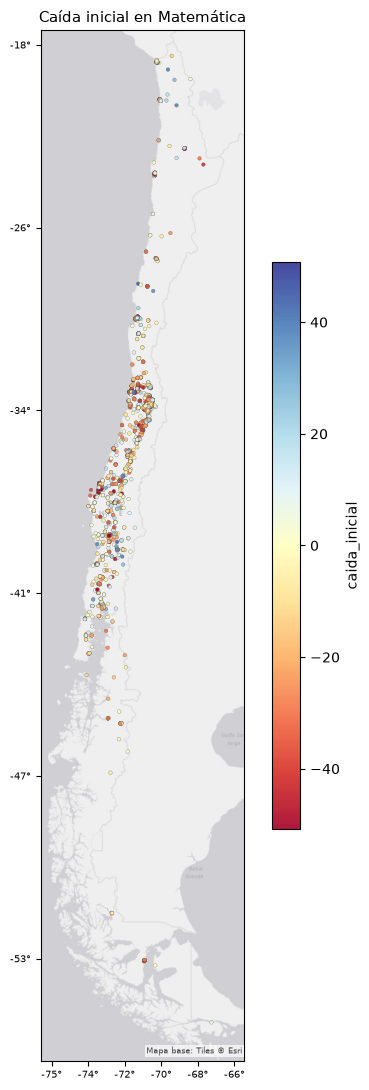

15:15:43 | INFO    | simce_panel.mapas | Descargando 30 mosaicos (zoom 6, proveedor 'gris').


15:15:44 | INFO    | simce_panel.mapas | Figura guardada en Dataset\Unificados\mapas\fig_residuo_caida.png


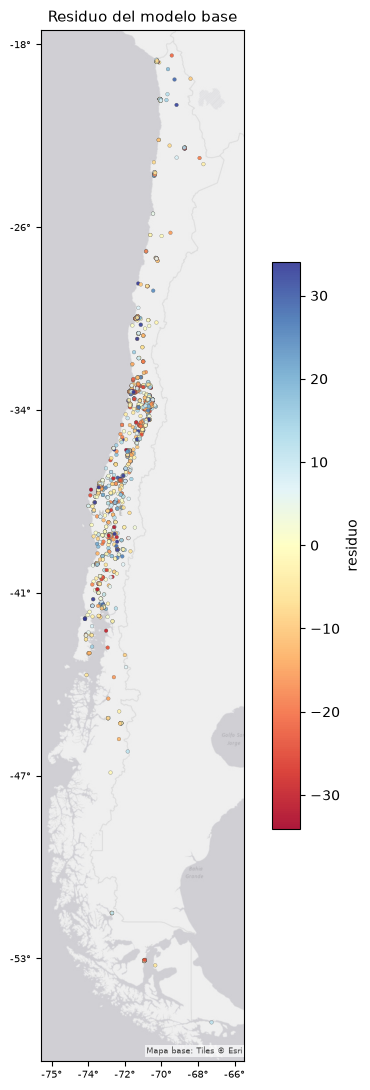

Mapas guardados en: Dataset\Unificados\mapas
  - fig_caida_inicial.png
  - fig_residuo_caida.png
  - mapa_caida_inicial.html
  - mapa_conglomerados_comunal.html
  - mapa_recuperacion.html
  - mapa_residuo_caida.html


In [19]:
import matplotlib.pyplot as plt

publicable = M.desplazar_coordenadas(d_caida, radio_m=300)
for col, titulo, archivo in [
        ("caida_inicial", "Caída inicial en Matemática", "fig_caida_inicial.png"),
        ("residuo", "Residuo del modelo base", "fig_residuo_caida.png")]:
    fig = M.mapa_estatico(publicable, col, titulo=titulo,
                          ruta_png=str(carpeta_mapas / archivo))
    plt.show()

print("Mapas guardados en:", carpeta_mapas)
for f in sorted(carpeta_mapas.iterdir()):
    print("  -", f.name)

## 6. Guardado de resultados

In [20]:
salida = m[["rbd", "latitud", "longitud", "caida_inicial", "recuperacion"]].copy()
for dep in ["caida_inicial", "recuperacion"]:
    l, d = lisa[(dep, "residuo")]
    salida = salida.merge(
        d[["rbd"]].assign(**{f"lisa_{dep}": l["conglomerado"].to_numpy(),
                             f"pfdr_{dep}": l["p_fdr"].to_numpy(),
                             f"residuo_{dep}": d["residuo"].to_numpy()}),
        on="rbd", how="left")

ruta = cfg.ruta_salida(f"espacial_{MATERIA}.csv")
sp.io_datos.escribir_csv(salida, ruta)
print("Guardado:", ruta, salida.shape)

Guardado: Dataset\Unificados\espacial_mate.csv (2821, 11)


---
### Interpretación de los resultados

El patrón a verificar en las salidas anteriores es el siguiente:

1. **Los niveles tienen estructura espacial; los cambios, mucho menos.** Si el Moran de `puntaje_pre` multiplica varias veces al de `caida_inicial`, la lectura es que la segregación determina dónde están los buenos y malos resultados, pero la pandemia no golpeó siguiendo un patrón geográfico propio.

2. **H1 es estadísticamente detectable pero sustantivamente despreciable.** Un Moran de residuos positivo y significativo confirma que queda algo de estructura, pero su magnitud determina si el hallazgo es sustantivo o meramente detectable por el tamaño muestral.

3. **Si ningún conglomerado sobrevive la corrección FDR, H2 no es contrastable** en su forma original. Ese resultado no es un fracaso técnico: indica que la recuperación no se concentró en territorios identificables, lo que contradice el supuesto de la focalización territorial y merece discutirse como hallazgo.

Estas conclusiones deben contrastarse con el profesor guía antes de fijar el alcance definitivo del capítulo.